## Module 2: FSHD Clinical Trial Project

By Tripp Hilderbrand and Skylar Falkner

## Project Goal:

This project uses natural-history data from 34 individuals with facioscapulohumeral muscular dystrophy (FSHD), followed over approximately two years, to investigate whether MRI-derived fat fraction may be a useful measure of disease progression. We use the existing cohort dataset to estimate right tibialis anterior (TA) fat fraction, TUG performance, and right-leg dorsiflexion strength at common time points using linear interpolation, allowing participants with different visit times to be compared more consistently.

Our analysis focuses on two research questions. Analysis A examines whether the rate of change in right TA fat fraction is associated with the rate of change in TUG time, a measure of functional mobility. Analysis B examines whether the rate of change in right TA fat fraction is associated with the rate of change in right-leg dorsiflexion strength. We also perform a separate MRI image analysis using water images, fat images, and muscle masks from one participant to demonstrate how fat fraction can be calculated from MRI data.

Together, these analyses explore whether MRI fat fraction may provide useful information about FSHD progression when considered alongside functional measures. Our goal is to assess its potential as an exploratory endpoint in an early-phase (Phase 1/2) FSHD clinical trial while considering the limitations of the available data, missing measurements, and interpolation estimates.

## Disease Background: 


### Prevalence & incidence

Facioscapulohumeral muscular dystrophy (FSHD) is a genetic disease that causes progressive weakening of skeletal muscle. FSHD affects about 4 in every 100,000 people. (URochester Medicine, n.d.)

https://www.urmc.rochester.edu/conditions-and-treatments/facioscapulohumeral-muscular-dystrophy 

### Symptoms

Symptoms of FSHD often include muscle facial weakness, shoulder weakness, lower leg weakness, abdominal weakness, posture changes, and chronic pain and inflammation affecting the shoulders, neck, legs, and back. (Muscular Dystrophy Association [MDA], 2026)

https://www.mda.org/disease/facioscapulohumeral-muscular-dystrophy/signs-and-symptoms 

### Diagnosis

To diagnose FSHD, doctors often run a series of tests including a blood test, neurological test, and a muscle biopsy. Doctors are specifically looking for muscle abnormalities during a biopsy and for specific blood enzymes, specifically serum creatine kinase (CK), an enzyme that is released into the blood stream when muscles start to deteriorate. To officially confirm an FSHD diagnosis, a genetic test is required. (FSHD Society, n.d.-b)

https://www.fshdsociety.org/living-with-fshd/understanding-fshd/diagnosis/ 

### Standard of care treatments (& reimbursement) 

There is no cure for FSHD, however healthcare providers often recommend physical therapy, orthotic devices and braces to support weak muscles, and sometimes surgical intervention. (Cleveland Clinic, 2023)

https://my.clevelandclinic.org/health/diseases/facioscapulohumeral-muscular-dystrophy-fshd 

### Disease progression & prognosis

Progression of FSHD is nonlinear and variable from person to person, however most people with FSHD can expect to live normal lifespans. However, some health issues may arise, including chronic pain, respiratory muscle difficulties or failure (uncommon), and other rare complications. Progression of the disease is typically slow and unpredictable. About 20% of people with FSH are wheelchair dependent. (Brun et al., 2026; Tawil et al., 2015; Cleveland Clinic, 2023)

https://www.sciencedirect.com/science/article/pii/S096089662600057X?__cf_chl_tk=CIgVRcGRWtwRWJuinNRvVYItpkjZlnPQAnesPHOAWjQ-1792107882-1.0.1.1-fslch.IFwagT.xzuBn_e_LBOuGKWDrGRP_RN23qaELc 

https://pmc.ncbi.nlm.nih.gov/articles/PMC4520817/ 

https://my.clevelandclinic.org/health/diseases/facioscapulohumeral-muscular-dystrophy-fshd 

### Biological mechanisms (anatomy, organ physiology, cell & molecular physiology)

There are two types of FSHD, separated into Type 1 and Type 2 and both cause the same symptoms. FSHD1 accounts for 95% of cases and occurs when the DUX4 gene that is supposed to be inactivated becomes activated. The reactivation of DUX4 is known to initiate the production of proteins that destroy muscle cells. FSHD2 accounts for the remaining 5% of cases and occurs when a different gene mutates or changes to turn on DUX4. As muscle fibers break down, healthy muscle is replaced by fat and scar tissue. The nuclei in muscle cells travels from the outside of the cell to the middle to coordinate cellular rebuilding. (Brun et al., 2026; Tawil et al., 2015)

https://www.sciencedirect.com/science/article/pii/S096089662600057X?__cf_chl_tk=CIgVRcGRWtwRWJuinNRvVYItpkjZlnPQAnesPHOAWjQ-1792107882-1.0.1.1-fslch.IFwagT.xzuBn_e_LBOuGKWDrGRP_RN23qaELc 

### Clinical Trials/next-gen therapies

There is no FDA approved treatment for FSHD. Most current clinical trials and therapies in development focus on controlling the expression of the DUX4 gene or reducing the harm of its expression. Most therapies are in phase 1 or 2 and focus on DUX4 expression using various antibody therapies, mRNA and RNA regimenes, and specific inhibition treatments of various proteins. (FSHD Society, n.d.-a)

Specific information about clinical trials was researched using a Consensus AI Pro subscription through the UVA library
https://consensus.app/search/fshd-clinical-trials-development/OTO7c9uoRCijwKJF7dxTYQ/?utm_source=share&utm_medium=clipboard 


## MRI Data Analysis Methodology:

Subject UW_0020, left tibialis anterior (TA), two visits (TP1 and TP2), eight cross-sectional samples per visit at locations 10% to 80% along the muscle. Each sample has a water image, a fat image, and a binary TA mask stored as NumPy arrays (266 x 224 pixels). `slice_info.csv` links each sample to its visit, percent location, and distance from the muscle start in mm.

The analysis has six steps: (1) load the metadata and the water, fat, and mask arrays; (2) compute fat fraction for each pixel; (3) use the mask to isolate the TA; (4) summarize the fat-fraction distribution (mean, median, SD, number of muscle pixels) for the whole image region and for the TA only; (5) repeat for all eight locations in each visit to build a profile along the muscle; (6) compare the two visits at matching percent locations and save a summary CSV.

### 1. Load the metadata and the image arrays

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

matches = list(Path.cwd().rglob("slice_info.csv"))
print("Found:", matches)
if not matches:
    raise FileNotFoundError("Could not find slice_info.csv. Put the data folder inside your project folder.")
DATA_DIR = matches[0].parent
manifest = pd.read_csv(DATA_DIR / "slice_info.csv")
manifest

Found: [PosixPath('/Users/tripphilderbrand/Desktop/VS Code/BME 2315/Module 2/BME2315_Module2 (fixed)/FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2/slice_info.csv')]


,subject,timepoint,slice_id,percent_along_muscle,z_index,distance_from_muscle_start_mm,water_file,fat_file,mask_file
0,UW_0020,TP1,1,10,41,24.0,TP1_slice_01_water.npy,TP1_slice_01_fat.npy,TP1_slice_01_mask.npy
1,UW_0020,TP1,2,20,46,44.0,TP1_slice_02_water.npy,TP1_slice_02_fat.npy,TP1_slice_02_mask.npy
2,UW_0020,TP1,3,30,52,68.0,TP1_slice_03_water.npy,TP1_slice_03_fat.npy,TP1_slice_03_mask.npy
3,UW_0020,TP1,4,40,58,92.0,TP1_slice_04_water.npy,TP1_slice_04_fat.npy,TP1_slice_04_mask.npy
4,UW_0020,TP1,5,50,64,116.0,TP1_slice_05_water.npy,TP1_slice_05_fat.npy,TP1_slice_05_mask.npy
5,UW_0020,TP1,6,60,69,136.0,TP1_slice_06_water.npy,TP1_slice_06_fat.npy,TP1_slice_06_mask.npy
6,UW_0020,TP1,7,70,75,160.0,TP1_slice_07_water.npy,TP1_slice_07_fat.npy,TP1_slice_07_mask.npy
7,UW_0020,TP1,8,80,81,184.0,TP1_slice_08_water.npy,TP1_slice_08_fat.npy,TP1_slice_08_mask.npy
8,UW_0020,TP2,1,10,40,24.0,TP2_slice_01_water.npy,TP2_slice_01_fat.npy,TP2_slice_01_mask.npy
9,UW_0020,TP2,2,20,46,48.0,TP2_slice_02_water.npy,TP2_slice_02_fat.npy,TP2_slice_02_mask.npy


Each row of the manifest names the water, fat, and mask files that belong together. The mask is converted to a boolean array (True = TA pixel).

In [11]:
row = manifest[manifest["timepoint"] == "TP1"].iloc[3]   # TP1, slice 04 (40% along muscle)

water = np.load(DATA_DIR / row["water_file"])
fat = np.load(DATA_DIR / row["fat_file"])
mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)

print("Water image shape:", water.shape)
print("Fat image shape:", fat.shape)
print("Mask shape:", mask.shape)
print("Number of muscle pixels:", mask.sum())

Water image shape: (266, 224)
Fat image shape: (266, 224)
Mask shape: (266, 224)
Number of muscle pixels: 360


### 2 and 3. Compute fat fraction and isolate the TA

For each pixel: **fat fraction (%) = fat signal / (water signal + fat signal) x 100.** The ratio is only calculated where the denominator is greater than zero, so empty pixels do not cause division by zero. The **whole image region** statistics use every pixel with signal in the supplied image half (other muscle, subcutaneous fat, bone, background). For the **TA-only** statistics, pixels outside the mask are set to NaN so they are ignored by the mean, median, and histogram.

In [13]:
denominator = water + fat
valid_pixels = denominator > 0

fat_fraction = np.divide(fat, denominator,
                         out=np.zeros_like(fat, dtype=float),
                         where=valid_pixels) * 100

fat_fraction_full = fat_fraction.copy()          # whole supplied image region
fat_fraction_masked = fat_fraction.copy()
fat_fraction_masked[~mask] = np.nan              # TA only

whole_image_values = fat_fraction_full[valid_pixels]
muscle_values = fat_fraction_masked[~np.isnan(fat_fraction_masked)]

print(f"Whole supplied image region - mean: {np.mean(whole_image_values):.1f}%")
print(f"Whole supplied image region - minimum: {np.min(whole_image_values):.1f}%")
print(f"Whole supplied image region - maximum: {np.max(whole_image_values):.1f}%")
print()
print(f"TA muscle only - mean: {np.mean(muscle_values):.1f}%")
print(f"TA muscle only - median: {np.median(muscle_values):.1f}%")
print(f"TA muscle only - SD: {np.std(muscle_values):.1f}%")
print(f"TA muscle only - minimum: {np.min(muscle_values):.1f}%")
print(f"TA muscle only - maximum: {np.max(muscle_values):.1f}%")
print(f"TA muscle only - number of pixels: {muscle_values.size}")

Whole supplied image region - mean: 48.6%
Whole supplied image region - minimum: 0.0%
Whole supplied image region - maximum: 100.0%

TA muscle only - mean: 29.9%
TA muscle only - median: 25.4%
TA muscle only - SD: 21.6%
TA muscle only - minimum: 0.5%
TA muscle only - maximum: 90.7%
TA muscle only - number of pixels: 360


### Figure 1: Water, fat, and fat-fraction images with the TA mask

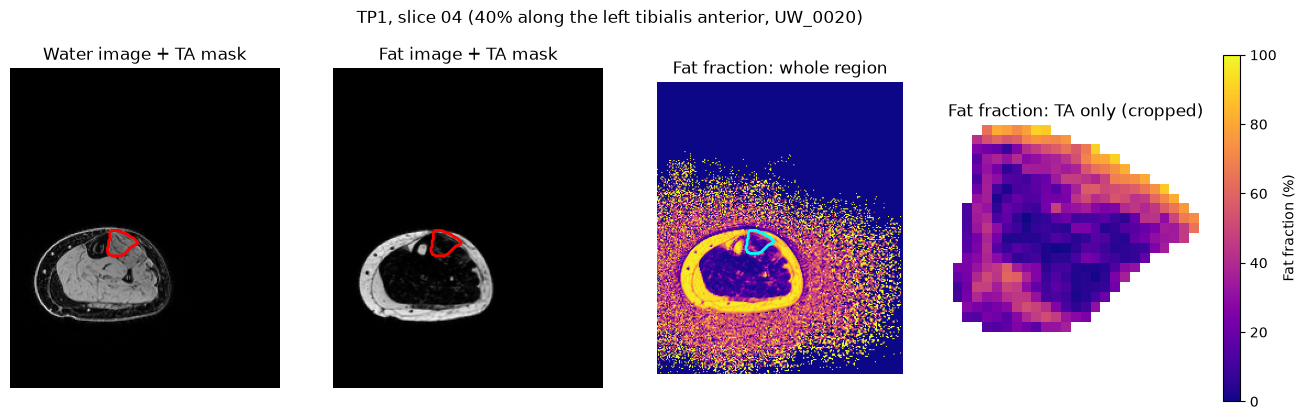

In [14]:
y_pixels, x_pixels = np.where(mask)
y0, y1 = y_pixels.min(), y_pixels.max() + 1
x0, x1 = x_pixels.min(), x_pixels.max() + 1
fat_fraction_TA = fat_fraction_masked[y0:y1, x0:x1]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))

axes[0].imshow(water, cmap="gray")
axes[0].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[0].set_title("Water image + TA mask")

axes[1].imshow(fat, cmap="gray")
axes[1].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[1].set_title("Fat image + TA mask")

axes[2].imshow(fat_fraction_full, cmap="plasma", vmin=0, vmax=100)
axes[2].contour(mask, levels=[0.5], colors="cyan", linewidths=2)
axes[2].set_title("Fat fraction: whole region")

ta_image = axes[3].imshow(fat_fraction_TA, cmap="plasma", vmin=0, vmax=100)
axes[3].set_title("Fat fraction: TA only (cropped)")

for ax in axes:
    ax.axis("off")      # pixel axes omitted; 1 pixel = 1.12 mm in-plane
fig.colorbar(ta_image, ax=axes[2:], fraction=0.046, pad=0.04, label="Fat fraction (%)")
fig.suptitle("TP1, slice 04 (40% along the left tibialis anterior, UW_0020)")
plt.show()

**Figure 1 caption.** Water and fat signal images (grayscale, arbitrary signal units) and the fat-fraction map (0 to 100%, colorbar) for one mid-muscle slice. The red/cyan outline is the TA segmentation mask. The figure is included to confirm that the mask sits on the TA and to show how much non-muscle anatomy (subcutaneous fat, other muscles, bone) surrounds it. The TA-only panel shows that fat is unevenly distributed inside the muscle.

### Figure 2: Fat-fraction distribution, whole region versus TA only

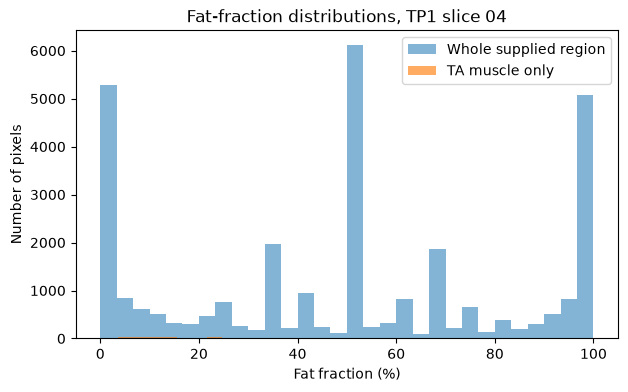

In [15]:
plt.figure(figsize=(7, 4))
plt.hist(whole_image_values, bins=30, alpha=0.55, label="Whole supplied region")
plt.hist(muscle_values, bins=30, alpha=0.65, label="TA muscle only")
plt.xlabel("Fat fraction (%)")
plt.ylabel("Number of pixels")
plt.title("Fat-fraction distributions, TP1 slice 04")
plt.legend()
plt.show()

**Figure 2 caption.** Histogram of fat fraction for all pixels with signal in the image half (blue) and for TA pixels only (orange). The whole-region mean is 48.6% but the TA mean is 29.9%, so including non-muscle pixels would overestimate fat in the muscle. The whole-region distribution also contains pixels at exactly 0% and 100%, which come from background and fat-only or water-only tissue rather than muscle. The TA-only distribution is broad and spans most of the 0 to 100% range, so a single mean does not describe it fully; the median and SD are reported alongside it for that reason.

### 4. Repeat for every sampled location and both visits

The calculation is wrapped in a function and applied to all eight slices for TP1 and TP2. For each slice we record the mean, median, SD, and number of TA pixels. The SD is the population SD (`np.nanstd`).

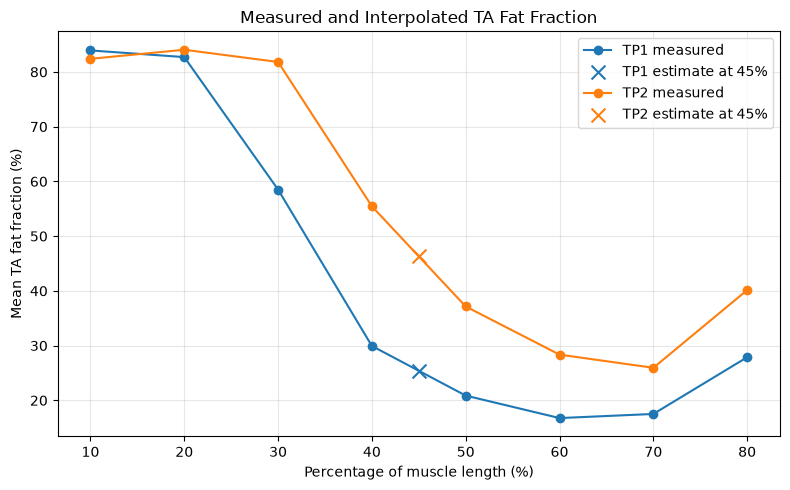

In [16]:
def calculate_fat_fraction(water, fat, mask):
    """Return a masked fat-fraction image in percent."""
    denominator = water + fat
    result = np.divide(fat, denominator,
                       out=np.zeros_like(fat, dtype=float),
                       where=denominator > 0) * 100
    result[~mask] = np.nan
    return result

results = []
for _, r in manifest.iterrows():
    w = np.load(DATA_DIR / r["water_file"])
    f = np.load(DATA_DIR / r["fat_file"])
    m = np.load(DATA_DIR / r["mask_file"]).astype(bool)
    ff = calculate_fat_fraction(w, f, m)
    results.append({
        "subject": r["subject"],
        "timepoint": r["timepoint"],
        "slice_id": r["slice_id"],
        "percent_along_muscle": r["percent_along_muscle"],
        "distance_from_muscle_start_mm": r["distance_from_muscle_start_mm"],
        "mean_fat_fraction_percent": np.nanmean(ff),
        "median_fat_fraction_percent": np.nanmedian(ff),
        "std_fat_fraction_percent": np.nanstd(ff),
        "n_muscle_pixels": int(m.sum()),
    })

results_df = pd.DataFrame(results)
results_df.round(2)

# Estimate fat fraction at 45% of the muscle length
target_percent = 45

plt.figure(figsize=(8, 5))

for timepoint, group in results_df.groupby("timepoint"):
    group = group.sort_values("percent_along_muscle")

    locations = group["percent_along_muscle"].to_numpy()
    fat_fraction = group["mean_fat_fraction_percent"].to_numpy()

    # Estimate the value between the measured 40% and 50% locations
    estimate = np.interp(
        target_percent,
        locations,
        fat_fraction
    )

    # Plot the measured values
    plt.plot(
        locations,
        fat_fraction,
        marker="o",
        label=f"{timepoint} measured"
    )

    # Mark the interpolated estimate
    plt.scatter(
        target_percent,
        estimate,
        marker="x",
        s=100,
        label=f"{timepoint} estimate at 45%"
    )

plt.xlabel("Percentage of muscle length (%)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Measured and Interpolated TA Fat Fraction")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Figure 3: Mean TA fat fraction along the muscle, TP1 versus TP2

The x-axis is the measured distance from the muscle start in mm, because the slices are not equally spaced in mm and the spacing differs slightly between visits.

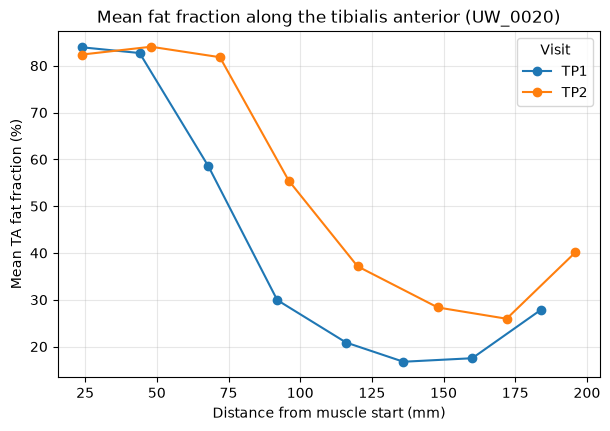

In [25]:
plt.figure(figsize=(7, 4.5))
for timepoint, group in results_df.groupby("timepoint"):
    group = group.sort_values("distance_from_muscle_start_mm")
    plt.plot(group["distance_from_muscle_start_mm"],
             group["mean_fat_fraction_percent"],
             marker="o", label=timepoint)
plt.xlabel("Distance from muscle start (mm)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Mean fat fraction along the tibialis anterior (UW_0020)")
plt.legend(title="Visit")
plt.grid(True, alpha=0.3)
plt.show()

**Figure 3 caption.** Mean fat fraction inside the TA mask at eight locations along the muscle, for each visit. It is included to show that fat fraction varies strongly along the muscle (it is high near both ends and lowest in the middle) and to compare visits. TP2 lies above TP1 at most locations. Because this is one subject at two visits, the plot illustrates the method and is not evidence of a population trend.

### 5. Compare visits at matching percent locations and save a summary file

The distance in mm differs between visits (for example 116 mm vs 120 mm at 50%), so visits are compared at the same **percent location** along the muscle. A change in MRI fat fraction indicates a change in muscle composition, but it is not by itself evidence that function improved or worsened.

In [26]:
comparison = results_df.pivot(index="percent_along_muscle",
                              columns="timepoint",
                              values="mean_fat_fraction_percent")
comparison["change_TP2_minus_TP1"] = comparison["TP2"] - comparison["TP1"]
display(comparison.round(2))

output_file = Path("TA_fat_fraction_summary.csv")
results_df.to_csv(output_file, index=False)
print(f"Saved {output_file}")

timepoint,TP1,TP2,change_TP2_minus_TP1
percent_along_muscle,,,
10,83.92,82.39,-1.53
20,82.71,84.05,1.34
30,58.50,81.82,23.32
40,29.93,55.45,25.52
50,20.87,37.15,16.28
60,16.76,28.35,11.59
70,17.51,25.95,8.43
80,27.87,40.14,12.27


Saved TA_fat_fraction_summary.csv


The MRI analysis focused on one participant, UW_0020, who had scans at two visits, TP1 and TP2. This sample came from a larger natural-history study of 34 individuals with FSHD who were followed for approximately two years. The purpose of this part of the project was to examine how fat fraction can be measured within a muscle using MRI images and how it varies along the muscle and between visits.

The images showed cross-sections of the participant’s left tibialis anterior (TA), a muscle located at the front of the lower leg. Eight locations were sampled along the muscle at each visit, for a total of 16 samples. Each image was stored as a NumPy array with 266 × 224 pixels. The images contained the half of the cross-section that included the TA, along with surrounding anatomy and background. Each pixel represented an area of approximately 1.116 × 1.116 mm, and the slices were spaced 4.0 mm apart [1, 2].

Each sample included a water image, a fat image, and a binary mask identifying the TA. The water and fat images showed the signals from water-containing tissue and fat, respectively. We calculated fat fraction for each pixel by dividing the fat signal by the combined water and fat signals and multiplying by 100. The binary mask was then used to focus the analysis on the TA itself, with pixels inside the muscle marked as 1 and pixels outside it marked as 0. These masks were provided with the dataset, so we did not have to create our own muscle segmentations [1, 2].

The eight image locations covered 10% to 80% of the muscle’s length, in increments of 10%. Because the distance in millimeters between locations was not evenly spaced and differed slightly between visits, we compared the two visits at matching percentage locations along the muscle. The graphs showing the distribution along the muscle used the recorded distances in millimeters, while the visit-to-visit comparison used percentage location [1, 3].

The original water and fat signals are measured in arbitrary scanner intensity units rather than physical units. However, their ratio produces a percentage, with 0% representing no fat signal and 100% representing only fat signal. Higher fat fraction within the TA can indicate greater fat replacement of muscle tissue, which is associated with FSHD progression. We calculated summary statistics, including the mean, median, and standard deviation, to describe fat fraction within the muscle and compared the values across the sampled locations and visits. The dataset also included a metadata file identifying each sample’s visit, slice, percentage location, distance from the muscle start, and file names. It did not contain clinical, biomarker, or functional measurements, so this image analysis was separate from our larger analysis of the 34-person cohort [1].

The course instructors provided the MRI data as a teaching dataset, and the accompanying README and course materials documented its contents [1–3].

**References**

1. README.md, “Student MRI sample: tibialis anterior at two visits,” course data folder `FSHD_TA_MRI_data_0020_TP1_TP2`.
2. `dataset_info.json` and `slice_info.csv`, same course data folder.
3. Course example notebook, `FSHD_TA_MRI_example_notebook.ipynb`.

## Interpolation Analysis:

To estimate fat fraction between the sampled locations along the tibialis anterior (TA), we used linear interpolation based on the percentage of muscle length. The MRI data included measurements at eight locations, ranging from 10% to 80% of the muscle length in increments of 10%. At each location, we calculated the mean fat fraction of the pixels inside the TA mask. We then used Python's `numpy.interp()` function to estimate fat fraction at 45% of the muscle length for both visits, using the measured values at the surrounding 40% and 50% locations.

Linear interpolation estimates a value between two measured points by assuming that fat fraction changes at a constant rate between them. The estimated value at 45% falls within the range of sampled locations, so this is interpolation rather than extrapolation. However, the estimate is not a new MRI measurement; it is calculated from existing measurements and depends on the assumption that the change between neighboring locations is approximately linear. Fat fraction may vary unevenly along the muscle, so the estimate may not match the actual value at an unsampled location. Additional limitations include the use of only eight sampled locations, the lack of measurements near both ends of the muscle, and the fact that the image analysis includes only one participant's left TA at two visits. The plot shows the measured fat-fraction values alongside the interpolated estimates to illustrate how this method fills the gaps between sampled locations.

In [6]:
from pathlib import Path
from module2patient import Patient
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy import stats


# Find the CSV in the same folder as this Python file
csv_path = Path.cwd() / "Module2_FSHD_Dataset (1).csv"

# Load all subjects from the CSV
Patient.instantiate_from_csv(str(csv_path))

print("Number of subjects =", len(Patient.all_patients))

# Print a few subjects to make sure the data loaded
for patient in Patient.all_patients[:5]:
    print(patient)


# Interpolation chunk for right tibialis anterior fat fraction,
# right-leg dorsiflexion strength, and TUG
# This will also give us a new CSV that we can use later


# Find the common comparison times for everyone
year1_times = []
year2_times = []

for patient in Patient.all_patients:
    if patient.lag_months_y1 is not None:
        year1_times.append(patient.lag_months_y1)

    if patient.lag_months_y2 is not None:
        year2_times.append(patient.lag_months_y2)

T1 = min(year1_times)
T2 = min(year2_times)

print(f"\nCommon Year 1 time: {T1:.2f} months")
print(f"Common Year 2 time: {T2:.2f} months")


# Estimate a value at a common time using a straight line
def linear_interpolation(times, values, target_time):

    times = np.array(times, dtype=float)
    values = np.array(values, dtype=float)

    # Ignore visits where the time or measurement is missing
    valid = np.isfinite(times) & np.isfinite(values)
    times = times[valid]
    values = values[valid]

    if len(times) < 2:
        return np.nan

    # Put the visits in order
    order = np.argsort(times, kind="stable")
    times = times[order]
    values = values[order]

    # If two visits have the same recorded time, keep the first one
    # so the interpolation uses different time points
    unique_times, indices = np.unique(times, return_index=True)
    times = unique_times
    values = values[indices]

    if len(times) < 2:
        return np.nan

    # Do not estimate outside the available measurements
    if target_time < times[0] or target_time > times[-1]:
        return np.nan

    line = interp1d(times, values, kind="linear")
    return float(line(target_time))


# Work through each subject and estimate all three measurements
results = []

for patient in Patient.all_patients:

    # Actual visit times for this subject
    times = [
        patient.lag_months_baseline,
        patient.lag_months_y1,
        patient.lag_months_y2
    ]

    # Keep the real baseline measurements separate from the estimates
    result = {
        "subject_id": patient.subject_id,

        "fat_fraction_baseline": patient.ff_baseline_R,
        "fat_fraction_linear_T1": linear_interpolation(
            times,
            [patient.ff_baseline_R, patient.ff_y1_R, patient.ff_y2_R],
            T1
        ),
        "fat_fraction_linear_T2": linear_interpolation(
            times,
            [patient.ff_baseline_R, patient.ff_y1_R, patient.ff_y2_R],
            T2
        ),

        "dorsiflexion_baseline": patient.dorsiflexion_qmt_R_baseline,
        "dorsiflexion_linear_T1": linear_interpolation(
            times,
            [
                patient.dorsiflexion_qmt_R_baseline,
                patient.dorsiflexion_qmt_R_y1,
                patient.dorsiflexion_qmt_R_y2
            ],
            T1
        ),
        "dorsiflexion_linear_T2": linear_interpolation(
            times,
            [
                patient.dorsiflexion_qmt_R_baseline,
                patient.dorsiflexion_qmt_R_y1,
                patient.dorsiflexion_qmt_R_y2
            ],
            T2
        ),

        "tug_baseline": patient.tug_time_baseline,
        "tug_linear_T1": linear_interpolation(
            times,
            [
                patient.tug_time_baseline,
                patient.tug_time_y1,
                patient.tug_time_y2
            ],
            T1
        ),
        "tug_linear_T2": linear_interpolation(
            times,
            [
                patient.tug_time_baseline,
                patient.tug_time_y1,
                patient.tug_time_y2
            ],
            T2
        )
    }

    results.append(result)


# Put all the estimates into a table so we can use them later
interpolated = pd.DataFrame(results)

print("\nExample interpolation results:")
print(interpolated.head())


# Calculate changes from baseline and average rates per year
measures = ["fat_fraction", "dorsiflexion", "tug"]

for measure in measures:

    baseline_column = f"{measure}_baseline"

    # Baseline is 0% change, as long as the baseline measurement exists
    # A zero baseline cannot be used to calculate percentage change
    baseline_values = interpolated[baseline_column].replace(0, np.nan)

    interpolated[f"{measure}_percent_change_baseline"] = np.where(
        baseline_values.notna(),
        0.0,
        np.nan
    )

    for timepoint, months in [("T1", T1), ("T2", T2)]:

        estimate_column = f"{measure}_linear_{timepoint}"
        change_column = f"{measure}_change_{timepoint}"
        rate_column = f"{measure}_rate_{timepoint}_per_year"
        percent_column = f"{measure}_percent_change_{timepoint}"

        # Change is the estimate minus the baseline measurement
        interpolated[change_column] = (
            interpolated[estimate_column] - interpolated[baseline_column]
        )

        # Divide by elapsed time in years
        interpolated[rate_column] = (
            interpolated[change_column] / (months / 12)
        )

        # Calculate percentage change for the point/line graphs
        interpolated[percent_column] = (
            (interpolated[estimate_column] - baseline_values)
            / baseline_values * 100
        )


# Print a simple summary of the changes
print("\nMean and median changes from baseline")

for measure in measures:

    print(f"\n{measure.replace('_', ' ').title()}")

    for timepoint in ["T1", "T2"]:

        changes = interpolated[
            f"{measure}_change_{timepoint}"
        ].dropna()

        rates = interpolated[
            f"{measure}_rate_{timepoint}_per_year"
        ].dropna()

        print(
            f"{timepoint}: n = {len(changes)}, "
            f"mean change = {changes.mean():.2f}, "
            f"median change = {changes.median():.2f}, "
            f"mean rate per year = {rates.mean():.2f}"
        )


# Save the estimates so we can use the same data later
output_path = Path.cwd() / "Module2_interpolation_results.csv"


interpolated.to_csv(output_path, index=False)

print(f"\nSaved interpolation results to: {output_path}")

Number of subjects = 34
1-0019: (M | Age = 47.06 | Right TA Fat Fraction = 5.977253243 | Right Dorsiflexion = 32.7 | TUG = 6.1)
1-0020: (F | Age = 24.28 | Right TA Fat Fraction = 10.82563624 | Right Dorsiflexion = 18.5 | TUG = 6.65)
1-0021: (M | Age = 36.42 | Right TA Fat Fraction = 3.346368298 | Right Dorsiflexion = 27.5 | TUG = 6.65)
1-0022: (F | Age = 59.43 | Right TA Fat Fraction = 5.476658791 | Right Dorsiflexion = 21.2 | TUG = 6.53)
1-0023: (M | Age = 63.92 | Right TA Fat Fraction = 26.59668028 | Right Dorsiflexion = 13.2 | TUG = 6.08)

Common Year 1 time: 11.15 months
Common Year 2 time: 22.13 months

Example interpolation results:
  subject_id  fat_fraction_baseline  fat_fraction_linear_T1  \
0     1-0019               5.977253                6.744922   
1     1-0020              10.825636                     NaN   
2     1-0021               3.346368                4.939927   
3     1-0022               5.476659                6.616676   
4     1-0023              26.596680   

### Cohort Data and Temporal Interpolation

After loading the dataset, we used the `Patient` class to organize measurements from the 34 participants with FSHD. Our analysis focused on three measurements: right tibialis anterior (TA) fat fraction, right-leg dorsiflexion strength, and Timed Up and Go (TUG) performance. Because participants did not all attend their follow-up visits at exactly the same times, we used linear interpolation to estimate measurements at two common time points: 11.15 months for Year 1 and 22.13 months for Year 2. These times were selected using the earliest recorded Year 1 and Year 2 visit times in the dataset.

For each participant, the code uses their available baseline, Year 1, and Year 2 measurements to estimate values at the common time points. Linear interpolation assumes that a measurement changes at a constant rate between two available observations. Missing measurements are excluded, and estimates are only calculated when the target time falls within the participant's available measurement range. Therefore, some participants have missing estimates and are not included in every part of the analysis.

After interpolation, we calculated the change from baseline for each measurement, the average rate of change per year, and the percentage change for use in our graphs. We then saved the results to a new CSV file so they could be used in the subsequent analyses. These estimates allowed us to compare participants more consistently despite differences in visit timing. However, interpolation provides estimates rather than new measurements, and assuming a linear change between visits may not fully represent how FSHD progresses in each individual.


Analysis A: Fat fraction vs. TUG
T1: n = 31, Pearson r = 0.262, p = 0.1547, Spearman rho = 0.309, p = 0.0909, slope = 0.173, R2 = 0.069, SE = 0.119
T2: n = 26, Pearson r = 0.201, p = 0.3238, Spearman rho = 0.231, p = 0.2553, slope = 0.076, R2 = 0.041, SE = 0.076


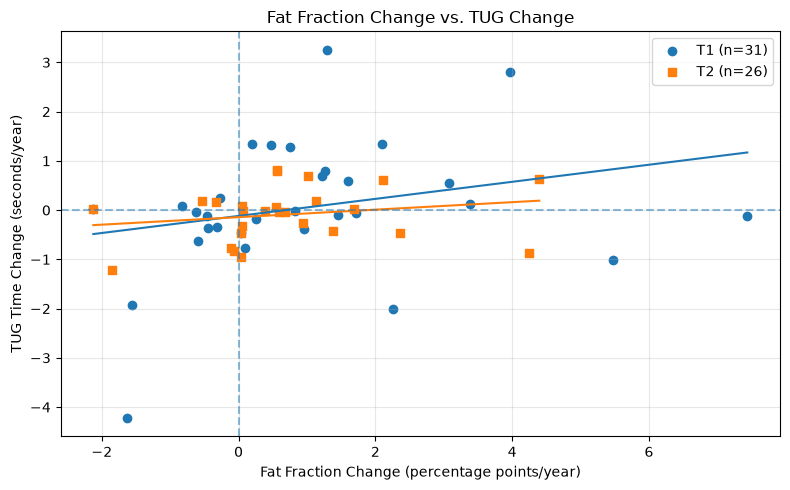

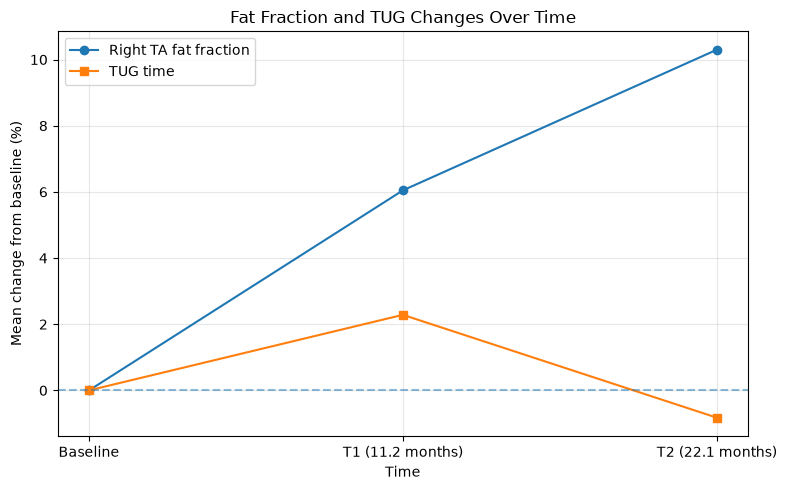

In [7]:
# Analysis A: Fat fraction change vs. TUG change

# Compare the average annual rate of change from baseline
# TUG is measured in seconds, so a positive change means a longer time


analysis_A_data = {}

print("\nAnalysis A: Fat fraction vs. TUG")

for timepoint in ["T1", "T2"]:

    fat_column = f"fat_fraction_rate_{timepoint}_per_year"
    tug_column = f"tug_rate_{timepoint}_per_year"

    # Only use subjects who have both measurements
    analysis_data = interpolated[
        [fat_column, tug_column]
    ].replace([np.inf, -np.inf], np.nan).dropna()

    fat_change = analysis_data[fat_column].to_numpy()
    tug_change = analysis_data[tug_column].to_numpy()

    n = len(analysis_data)

    if (
        n >= 3
        and len(np.unique(fat_change)) > 1
        and len(np.unique(tug_change)) > 1
    ):

        # Pearson and Spearman correlations
        pearson_r, pearson_p = stats.pearsonr(
            fat_change, tug_change
        )

        spearman_r, spearman_p = stats.spearmanr(
            fat_change, tug_change
        )

        # Linear regression
        slope, intercept, r_value, p_value, standard_error = stats.linregress(
            fat_change, tug_change
        )

        r_squared = r_value ** 2

        print(
            f"{timepoint}: n = {n}, "
            f"Pearson r = {pearson_r:.3f}, p = {pearson_p:.4f}, "
            f"Spearman rho = {spearman_r:.3f}, "
            f"p = {spearman_p:.4f}, "
            f"slope = {slope:.3f}, R2 = {r_squared:.3f}, "
            f"SE = {standard_error:.3f}"
        )

        analysis_A_data[timepoint] = (
            fat_change, tug_change, slope, intercept
        )

    else:
        print(f"{timepoint}: n = {n}, not enough usable data for testing")


# Scatter plot for Analysis A: show T1 and T2 together
plt.figure(figsize=(8, 5))

for timepoint, color, marker in [
    ("T1", "C0", "o"),
    ("T2", "C1", "s")
]:

    if timepoint in analysis_A_data:

        fat_change, tug_change, slope, intercept = analysis_A_data[timepoint]

        plt.scatter(
            fat_change,
            tug_change,
            color=color,
            marker=marker,
            label=f"{timepoint} (n={len(fat_change)})"
        )

        # Add a trend line for each time point
        line_x = np.linspace(
            min(fat_change), max(fat_change), 100
        )
        line_y = intercept + slope * line_x

        plt.plot(line_x, line_y, color=color)

plt.xlabel("Fat Fraction Change (percentage points/year)")
plt.ylabel("TUG Time Change (seconds/year)")
plt.title("Fat Fraction Change vs. TUG Change")
plt.axhline(y=0, linestyle="--", alpha=0.5)
plt.axvline(x=0, linestyle="--", alpha=0.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Point/line graph for Analysis A: average percentage change over time
time_labels = [
    "Baseline",
    f"T1 ({T1:.1f} months)",
    f"T2 ({T2:.1f} months)"
]

fat_means = [
    interpolated["fat_fraction_percent_change_baseline"].mean(),
    interpolated["fat_fraction_percent_change_T1"].mean(),
    interpolated["fat_fraction_percent_change_T2"].mean()
]

tug_means = [
    interpolated["tug_percent_change_baseline"].mean(),
    interpolated["tug_percent_change_T1"].mean(),
    interpolated["tug_percent_change_T2"].mean()
]

plt.figure(figsize=(8, 5))
plt.plot(time_labels, fat_means, marker="o", label="Right TA fat fraction")
plt.plot(time_labels, tug_means, marker="s", label="TUG time")
plt.xlabel("Time")
plt.ylabel("Mean change from baseline (%)")
plt.title("Fat Fraction and TUG Changes Over Time")
plt.axhline(y=0, linestyle="--", alpha=0.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


This analysis investigated whether changes in right tibialis anterior (TA) fat fraction were associated with changes in Timed Up and Go (TUG) performance. Linear interpolation was used to estimate measurements at two common follow-up times, 11.15 months (T1) and 22.13 months (T2). Scatter plots, correlation tests, and linear regression were used to examine the relationship between the annual rates of change in the two measures, while a point/line graph compared their average percentage changes from baseline over time. Both follow-up time points showed weak positive correlations, but neither was statistically significant (T1: r = 0.262, p = 0.155; T2: r = 0.201, p = 0.324). These findings do not provide sufficient evidence of an association between fat fraction changes and TUG performance in this sample. Because a higher TUG time indicates slower performance and participants had missing measurements, the results should be interpreted cautiously.


Analysis B: Fat fraction vs. dorsiflexion strength
T1: n = 24, Pearson r = 0.134, p = 0.5320, Spearman rho = 0.090, p = 0.6743, slope = 0.566, R2 = 0.018, SE = 0.892
T2: n = 23, Pearson r = -0.095, p = 0.6653, Spearman rho = -0.158, p = 0.4712, slope = -0.178, R2 = 0.009, SE = 0.405


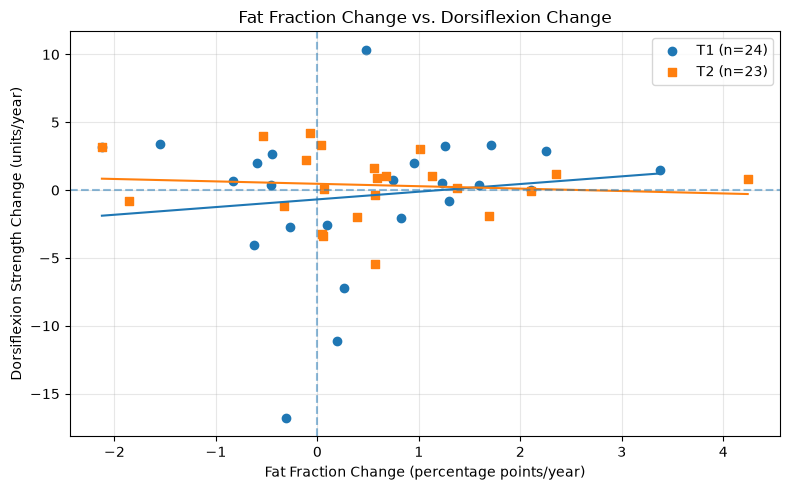

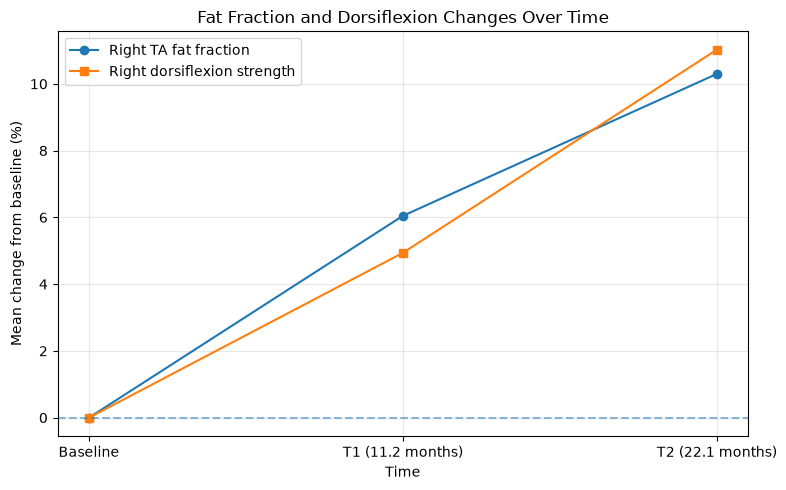

In [8]:
# Analysis B: Fat fraction change vs. dorsiflexion strength change

# Compare the average annual rate of change from baseline
# A negative dorsiflexion change means strength has decreased


analysis_B_data = {}

print("\nAnalysis B: Fat fraction vs. dorsiflexion strength")

for timepoint in ["T1", "T2"]:

    fat_column = f"fat_fraction_rate_{timepoint}_per_year"
    strength_column = f"dorsiflexion_rate_{timepoint}_per_year"

    # Only use subjects who have both measurements
    analysis_data = interpolated[
        [fat_column, strength_column]
    ].replace([np.inf, -np.inf], np.nan).dropna()

    fat_change = analysis_data[fat_column].to_numpy()
    strength_change = analysis_data[strength_column].to_numpy()

    n = len(analysis_data)

    if (
        n >= 3
        and len(np.unique(fat_change)) > 1
        and len(np.unique(strength_change)) > 1
    ):

        # Pearson and Spearman correlations
        pearson_r, pearson_p = stats.pearsonr(
            fat_change, strength_change
        )

        spearman_r, spearman_p = stats.spearmanr(
            fat_change, strength_change
        )

        # Linear regression
        slope, intercept, r_value, p_value, standard_error = stats.linregress(
            fat_change, strength_change
        )

        r_squared = r_value ** 2

        print(
            f"{timepoint}: n = {n}, "
            f"Pearson r = {pearson_r:.3f}, p = {pearson_p:.4f}, "
            f"Spearman rho = {spearman_r:.3f}, "
            f"p = {spearman_p:.4f}, "
            f"slope = {slope:.3f}, R2 = {r_squared:.3f}, "
            f"SE = {standard_error:.3f}"
        )

        analysis_B_data[timepoint] = (
            fat_change, strength_change, slope, intercept
        )

    else:
        print(f"{timepoint}: n = {n}, not enough usable data for testing")


# Scatter plot for Analysis B: show T1 and T2 together
plt.figure(figsize=(8, 5))

for timepoint, color, marker in [
    ("T1", "C0", "o"),
    ("T2", "C1", "s")
]:

    if timepoint in analysis_B_data:

        fat_change, strength_change, slope, intercept = analysis_B_data[timepoint]

        plt.scatter(
            fat_change,
            strength_change,
            color=color,
            marker=marker,
            label=f"{timepoint} (n={len(fat_change)})"
        )

        # Add a trend line for each time point
        line_x = np.linspace(
            min(fat_change), max(fat_change), 100
        )
        line_y = intercept + slope * line_x

        plt.plot(line_x, line_y, color=color)

plt.xlabel("Fat Fraction Change (percentage points/year)")
plt.ylabel("Dorsiflexion Strength Change (units/year)")
plt.title("Fat Fraction Change vs. Dorsiflexion Change")
plt.axhline(y=0, linestyle="--", alpha=0.5)
plt.axvline(x=0, linestyle="--", alpha=0.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Point/line graph for Analysis B: average percentage change over time

strength_means = [
    interpolated["dorsiflexion_percent_change_baseline"].mean(),
    interpolated["dorsiflexion_percent_change_T1"].mean(),
    interpolated["dorsiflexion_percent_change_T2"].mean()
]

plt.figure(figsize=(8, 5))
plt.plot(time_labels, fat_means, marker="o", label="Right TA fat fraction")
plt.plot(time_labels, strength_means, marker="s", label="Right dorsiflexion strength")
plt.xlabel("Time")
plt.ylabel("Mean change from baseline (%)")
plt.title("Fat Fraction and Dorsiflexion Changes Over Time")
plt.axhline(y=0, linestyle="--", alpha=0.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


This analysis investigated whether changes in right tibialis anterior (TA) fat fraction were associated with changes in right-leg dorsiflexion strength. Linear interpolation was used to estimate measurements at two common follow-up times, 11.15 months (T1) and 22.13 months (T2). Scatter plots, correlation tests, and linear regression were used to examine the relationship between the annual rates of change in the two measures, while a point/line graph compared their average percentage changes from baseline over time. The results showed a weak positive correlation at T1 (r = 0.134, p = 0.532) and a weak negative correlation at T2 (r = −0.095, p = 0.665). Neither correlation was statistically significant, so the results do not provide sufficient evidence of an association between changes in fat fraction and dorsiflexion strength in this sample. Because a negative change in dorsiflexion strength indicates a decrease in strength and participants had missing measurements, these findings should be interpreted cautiously.


## Conclusions

Our analysis suggests that MRI fat fraction may be a useful measure for tracking FSHD progression, particularly when considered alongside functional measurements. In the cohort analysis, mean right tibialis anterior (TA) fat fraction increased by 0.93 percentage points at the first common time point (11.15 months) and 1.26 percentage points at the second (22.13 months). The median changes were also positive at both time points, suggesting that fat fraction increased for a substantial portion of participants. However, the number of participants with usable estimates decreased from 31 at T1 to 26 at T2, and interpolation provided estimates rather than direct measurements at these exact times. The results should therefore be interpreted cautiously.

Our separate MRI image analysis provided additional insight into how fat fraction varies within a muscle. In the left TA of one participant, fat fraction varied noticeably across the eight sampled locations, with higher values near the ends of the muscle and lower values near the middle. Fat fraction was also higher at the second visit at most sampled locations. This suggests that both the location within a muscle and the timing of a scan can affect the results. However, because this analysis included only one participant and two visits, it cannot establish that the same pattern occurs across the wider FSHD population. Consistent positioning and comparison of the same muscle regions would be important when using MRI fat fraction in future studies.

We also examined whether changes in right TA fat fraction were associated with changes in TUG performance and right-leg dorsiflexion strength. In Analysis A, the correlations between fat fraction change and TUG time change were weakly positive at both T1 (*r* = 0.262, *p* = 0.155) and T2 (*r* = 0.201, *p* = 0.324). In Analysis B, the relationship with dorsiflexion strength was weakly positive at T1 (*r* = 0.134, *p* = 0.532) and weakly negative at T2 (*r* = −0.095, *p* = 0.665). None of these correlations was statistically significant, so our results do not provide sufficient evidence that changes in fat fraction were associated with changes in either functional measure. This does not necessarily mean that no relationship exists; the small sample, missing measurements, and differences between participants may have limited our ability to detect one.

The functional measures also showed less consistent patterns of change than fat fraction. The mean TUG time increased slightly at T1 but decreased at T2, while the mean dorsiflexion strength decreased slightly at T1 and increased at T2. Their median changes did not always follow the same direction as their means, showing that individual responses varied. The Clinical Severity Score and other biomarkers were not directly evaluated for longitudinal change in our analysis, so we cannot determine how consistently they changed or whether they were more sensitive to progression. Based on the measures we analyzed, fat fraction showed the clearest consistent direction of average change, but we cannot conclude that it was the most sensitive or reliable measure overall.

MRI fat fraction, dorsiflexion strength, and TUG performance are therefore reasonable candidates for further investigation as exploratory endpoints in early-phase FSHD clinical trials. Each captures a different aspect of the disease: MRI measures changes in muscle composition, dorsiflexion strength measures muscle function, and TUG assesses mobility. Using multiple measures could provide a more complete picture than relying on imaging or functional testing alone. However, our study used natural-history data rather than testing a treatment, so it cannot show whether any of these measures would be able to detect a treatment effect.

Before these measures could be used confidently to evaluate treatment effectiveness, larger studies with more complete follow-up and additional time points would be needed. Researchers should assess measurement reliability, including scan-rescan variability for MRI, and determine whether observed changes are larger than expected measurement error. Confidence intervals, effect sizes, and comparisons with meaningful changes in participants' daily functioning would help establish how sensitive and clinically useful each measure is. Further studies should also compare changes in MRI fat fraction with changes in strength, mobility, and clinical severity in the same participants, followed by clinical trials to determine whether the measures respond to treatment.

Finally, selecting clinical-trial endpoints has ethical and practical implications. MRI can provide detailed information about muscle composition, but it is expensive and may not be equally accessible to all patients. Specialized testing can also increase the time and burden required to participate in a trial. At the same time, focusing only on MRI changes could overlook improvements or declines in strength, mobility, or daily activities that matter directly to patients. Endpoint selection should balance scientific reliability, sensitivity to change, accessibility, participant burden, and relevance to quality of life. Overall, our findings support further investigation of MRI fat fraction alongside functional measures, rather than selecting a single endpoint as the best indicator of FSHD progression.

## Limitations and Future Work

### Limitations

One limitation of this project is the size and scope of the data. Our MRI image analysis focused on one participant, UW_0020, and the left tibialis anterior (TA) at two visits. It demonstrated how fat fraction is calculated from MRI images but cannot establish general patterns of FSHD progression. Our separate cohort analysis used data from 34 participants, although missing measurements meant that fewer participants contributed to each analysis. Fat fraction estimates were available for 31 participants at T1 and 26 at T2, while Analysis B included 24 participants at T1 and 23 at T2.

Because participants attended visits at different times, we used linear interpolation to estimate measurements at common time points of 11.15 and 22.13 months. These estimates assume that measurements change at a constant rate between visits, which may not reflect actual disease progression. The MRI image analysis also sampled only eight locations along the muscle, and fat fraction varied across these locations. Therefore, measurement location can affect the results. Additionally, the provided muscle masks were not independently validated, and we did not evaluate MRI scan-rescan reliability or account for potential scanner-related effects. Small changes could therefore reflect measurement variability rather than actual changes in muscle composition.

The two analyses were also not directly connected computationally. The image analysis calculated fat fraction from the left TA images of one participant, while the cohort analysis used existing right TA fat-fraction values from the CSV dataset. Although we examined associations between fat fraction, TUG performance, and dorsiflexion strength, neither relationship was statistically significant. This does not prove that no relationship exists, as the small sample and missing data may have limited our ability to detect one. We also did not directly analyze longitudinal changes in the Clinical Severity Score or other biomarkers. Finally, because our data came from a natural-history study rather than a treatment trial, we cannot determine whether these measures would detect treatment effects.

### Future Work

Future research could include MRI data from more participants, additional muscles, and more follow-up visits. This would provide a more complete understanding of fat fraction changes and reduce the need for interpolation. Researchers should also assess scan-rescan reliability and validate muscle masks to determine whether observed changes exceed measurement error.

Larger studies with more complete data could compare MRI fat fraction with dorsiflexion strength, TUG performance, the Clinical Severity Score, and relevant biomarkers in the same participants. Confidence intervals and effect sizes would help evaluate the reliability and sensitivity of these measures. Clinical trials involving treated participants would then be needed to determine whether the measures can detect treatment effects.

Endpoint selection should also consider accessibility and patient relevance. MRI can provide detailed information about muscle composition but is expensive and may not be available to everyone. Functional tests provide complementary information about strength and mobility that may matter more directly to daily life. Combining imaging and functional measures may therefore provide a more complete assessment of FSHD progression than relying on a single endpoint.

## AI Usage Statement:
We used Claude Code to help with the Methods Analysis section and debugging code throughout. It was also used to help with clearly labeling the generated figures and fixing formatting issues.

ChatGPT 6 was used to assist with syntax and understanding of interpolation analysis, debugging, and graph generation code. The internal VS code AI agent was utilized to help with indentation-related errors.Pythontutorial.net was utilized for additional understanding of general syntax.

## GitHub Repository Link:
https://github.com/tripphilderbrand/BME2315_Module2-fixed-


## References:

1. URochester Medicine. (n.d.). *Facioscapulohumeral muscular dystrophy (FSHD).* https://www.urmc.rochester.edu/conditions-and-treatments/facioscapulohumeral-muscular-dystrophy

2. Muscular Dystrophy Association. (2026, April). *Signs and symptoms of facioscapulohumeral muscular dystrophy (FSHD).* https://www.mda.org/disease/facioscapulohumeral-muscular-dystrophy/signs-and-symptoms

3. FSHD Society. (n.d.-b). *Diagnosis.* https://www.fshdsociety.org/living-with-fshd/understanding-fshd/diagnosis/

4. Cleveland Clinic. (2023, December 6). *FSHD (facioscapulohumeral muscular dystrophy).* https://my.clevelandclinic.org/health/diseases/facioscapulohumeral-muscular-dystrophy-fshd

5. Brun, B. N., Camarta, N., Johnson, N., & Schoser, B. (2026). Overview of facioscapulohumeral dystrophy clinical features and diagnostic pathway. *Neuromuscular Disorders, 61*, Article 106389. https://doi.org/10.1016/j.nmd.2026.106389

6. Tawil, R., Kissel, J. T., Heatwole, C., Pandya, S., Gronseth, G., & Benatar, M. (2015). Evidence-based guideline summary: Evaluation, diagnosis, and management of facioscapulohumeral muscular dystrophy. *Neurology, 85*(4), 357–364. https://doi.org/10.1212/WNL.0000000000001783

7. FSHD Society. (n.d.-a). *Current trials and studies.* Retrieved October 22, 2026, from https://www.fshdsociety.org/research-and-clinical-care/current-trials-and-studies/